In [24]:
%pip install pandas # installed pandas
import pandas as pd # imported as pd
import numpy as np # imported as np
import matplotlib.pyplot as plt # imported as plt


[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
# starting project 2 

df = pd.read_csv('/Users/pragya.sharma/Downloads/archive/GlobalLandTemperaturesByCountry.csv')  # read the dataset 2 as a csv file
df 

,dt,AverageTemperature,AverageTemperatureUncertainty,Country
0,1743-11-01,4.384,2.294,Åland
1,1743-12-01,NaN,NaN,Åland
2,1744-01-01,NaN,NaN,Åland
3,1744-02-01,NaN,NaN,Åland
4,1744-03-01,NaN,NaN,Åland
...,...,...,...,...
577457,2013-05-01,19.059,1.022,Zimbabwe
577458,2013-06-01,17.613,0.473,Zimbabwe
577459,2013-07-01,17.000,0.453,Zimbabwe
577460,2013-08-01,19.759,0.717,Zimbabwe


In [33]:
filtered_df = df[df['dt'].isin(['1997-01-01', '2013-01-01'])] # filtered the dataset to only have the years 1997 and 2017
filtered_df

,dt,AverageTemperature,AverageTemperatureUncertainty,Country
3038,1997-01-01,-0.646,0.497,Åland
3230,2013-01-01,-2.569,0.603,Åland
5144,1997-01-01,2.690,0.521,Afghanistan
5336,2013-01-01,2.241,0.516,Afghanistan
7109,1997-01-01,21.859,0.201,Africa
...,...,...,...,...
573523,2013-01-01,21.567,0.680,Yemen
575296,1997-01-01,22.407,0.471,Zambia
575488,2013-01-01,23.072,1.190,Zambia
577261,1997-01-01,23.202,0.210,Zimbabwe


In [34]:
pivot_df = filtered_df.pivot(index='Country', columns='dt', values='AverageTemperature').dropna()
pivot_df.columns = ['Temp_1997', 'Temp_2013']




In [36]:
x = pivot_df['Temp_1997']
y = pivot_df['Temp_2013']



In [22]:
slope = x.cov(y) / x.var()
intercept = y.mean() - slope * x.mean()
regression_line = slope * x + intercept

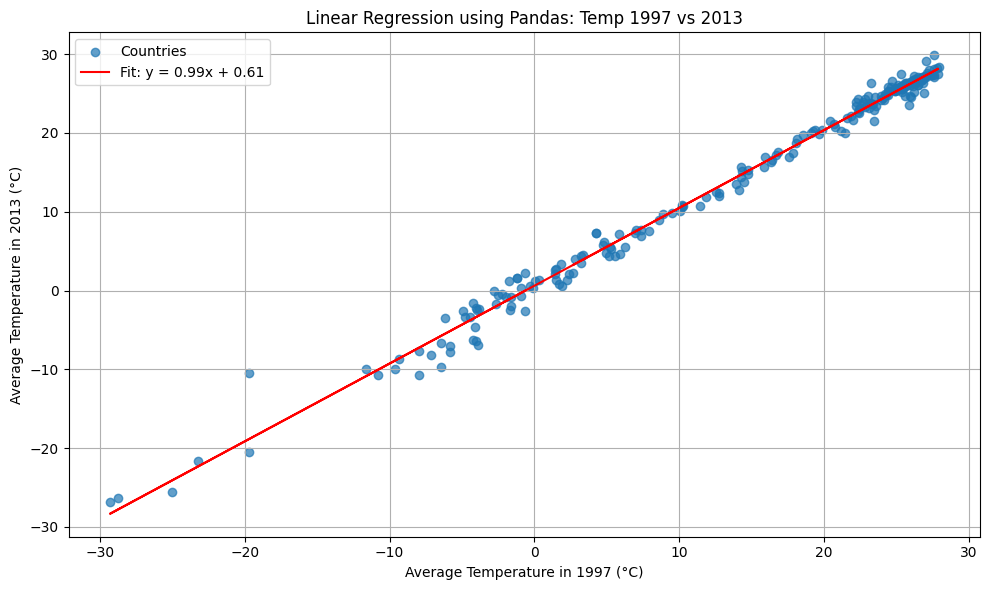

In [38]:
plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.7, label='Countries')
plt.plot(x, regression_line, color='red', label=f'Fit: y = {slope:.2f}x + {intercept:.2f}')
plt.xlabel('Average Temperature in 1997 (°C)')
plt.ylabel('Average Temperature in 2013 (°C)')
plt.title('Linear Regression using Pandas: Temp 1997 vs 2013')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()